In [3]:
# Our Business Question for this notebook for Project 2.
# Does showing customers an advertisement improve purchase conversion compared with showing a neutral public service announcement?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

ab_df = pd.read_csv('marketing_AB.csv')

display(ab_df.head())
print(ab_df.shape)

,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


(588101, 7)


In [2]:
# Check missing values
print(ab_df.isnull().sum())

# Check duplicate customers
print("Duplicate Users:", ab_df['user id'].duplicated().sum())

# Check experiment group sizes
print(ab_df['test group'].value_counts())

Unnamed: 0       0
user id          0
test group       0
converted        0
total ads        0
most ads day     0
most ads hour    0
dtype: int64
Duplicate Users: 0
test group
ad     564577
psa     23524
Name: count, dtype: int64


In [4]:
# Business question: Did customers who saw advertisements convert more frequently than customers in the control group?

ab_results = ab_df.groupby('test group')['converted'].agg(
    ['count', 'sum', 'mean']
)

ab_results['mean'] = ab_results['mean'] * 100

ab_results.columns = [
    'total_users',
    'conversions',
    'conversion_rate_pct'
]

display(ab_results.round(2))

,total_users,conversions,conversion_rate_pct
test group,,,
ad,564577,14423,2.55
psa,23524,420,1.79


In [5]:
# Business question: How much better did the advertisement perform?

ad_rate = ab_results.loc['ad', 'conversion_rate_pct']
psa_rate = ab_results.loc['psa', 'conversion_rate_pct']

absolute_lift = ad_rate - psa_rate

relative_lift = (absolute_lift / psa_rate) * 100

print("Absolute Lift:", round(absolute_lift, 2), "percentage points")
print("Relative Lift:", round(relative_lift, 2), "%")

Absolute Lift: 0.77 percentage points
Relative Lift: 43.09 %


In [6]:
# Business question: Is this conversion difference statistically significant, or could it be explained by random variation?

from statsmodels.stats.proportion import proportions_ztest

# Number of conversions
conversions = [14423, 420]

# Total users in each group
users = [564577, 23524]

# Perform Z-Test
z_score, p_value = proportions_ztest(conversions, users)

print("Z-Score:", round(z_score, 2))
print("P-Value:", round(p_value, 5))

Z-Score: 7.37
P-Value: 0.0


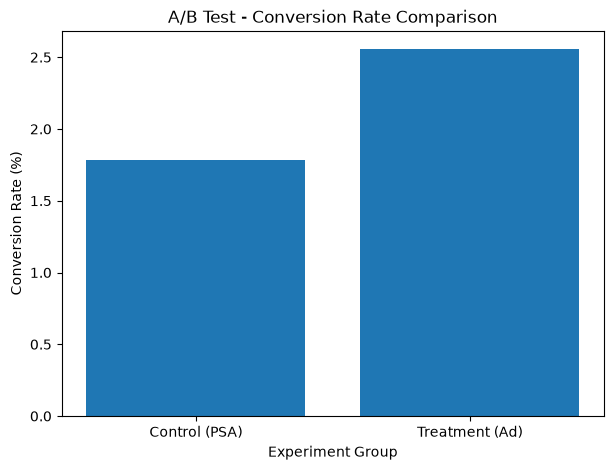

In [7]:
plt.figure(figsize=(7, 5))

plt.bar(
    ['Control (PSA)', 'Treatment (Ad)'],
    [psa_rate, ad_rate]
)

plt.title('A/B Test - Conversion Rate Comparison')
plt.xlabel('Experiment Group')
plt.ylabel('Conversion Rate (%)')

plt.show()